In [2]:
from pathlib import Path
import collections, random
from PIL import Image

base = next(Path("/kaggle/input").rglob("Orignal-Dataset")).parent
print("base:", base)
exts = {".jpg", ".jpeg", ".png"}

for sub in ["Orignal-Dataset", "CyAUG-Dataset"]:
    print(f"\n{sub}")
    total = 0
    for cls in sorted((base / sub).iterdir()):
        files = [f for f in cls.iterdir() if f.suffix.lower() in exts]
        total += len(files)
        print(f"  {cls.name:15s} {len(files)}")
    print("  TOTAL:", total)

for sub in ["Orignal-Dataset", "CyAUG-Dataset"]:
    cls = sorted((base / sub).iterdir())[0]
    files = sorted(cls.iterdir())
    print(f"\n{sub}/{cls.name} first filenames:", [f.name for f in files[:6]])
    sizes = collections.Counter(Image.open(f).size for f in random.sample(files, min(20, len(files))))
    print("  image sizes:", sizes.most_common(3))

base: /kaggle/input/datasets/ai4a-lab/comprehensive-soil-classification-datasets

Orignal-Dataset
  Alluvial_Soil   51
  Arid_Soil       284
  Black_Soil      255
  Laterite_Soil   219
  Mountain_Soil   201
  Red_Soil        109
  Yellow_Soil     69
  TOTAL: 1188

CyAUG-Dataset
  Alluvial_Soil   692
  Arid_Soil       284
  Black_Soil      1173
  Laterite_Soil   219
  Mountain_Soil   201
  Red_Soil        1126
  Yellow_Soil     1401
  TOTAL: 5096

Orignal-Dataset/Alluvial_Soil first filenames: ['1.jpg', '10.jpg', '100.jpg', '101.jpg', '103.jpg', '104.jpg']
  image sizes: [((482, 421), 1), ((1425, 1200), 1), ((1000, 466), 1)]

CyAUG-Dataset/Alluvial_Soil first filenames: ['1.jpg', '10.jpg', '100.jpg', '101.jpg', '103.jpg', '104.jpg']
  image sizes: [((256, 256), 19), ((1188, 240), 1)]


In [3]:
import os, hashlib, pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

exts = {".jpg", ".jpeg", ".png"}

def list_files(sub, tag):
    rows = []
    for cls in sorted((base / sub).iterdir()):
        with os.scandir(cls) as it:
            for e in it:
                if Path(e.name).suffix.lower() in exts:
                    rows.append(dict(path=e.path, label=cls.name, name=e.name,
                                     size=e.stat().st_size, folder=tag))
    return pd.DataFrame(rows)

orig = list_files("Orignal-Dataset", "orig")
cy = list_files("CyAUG-Dataset", "cyaug")

# Same name + same size + same class folder => CyAUG copy of an original
key = lambda d: d.label + "/" + d.name + "/" + d["size"].astype(str)
orig_keys = set(key(orig))
cy["is_original_copy"] = key(cy).isin(orig_keys)

# Duplicate photos inside Original (cheap fingerprint: first 64 KB + file size)
def fp(path, size):
    with open(path, "rb") as f:
        return hashlib.md5(f.read(65536)).hexdigest() + str(size)
orig["fp"] = [fp(p, s) for p, s in zip(orig.path, orig["size"])]
print("duplicate images inside Original:", orig.fp.duplicated().sum())
orig = orig.drop_duplicates("fp")

print("\nCyAUG files that are copies of originals vs. GAN-generated:")
print(cy.groupby("label").is_original_copy.agg(copies="sum", total="count"))

tr, tmp = train_test_split(orig, test_size=0.30, stratify=orig.label, random_state=42)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=42)
synth = cy[~cy.is_original_copy]    # GAN images only, never used for val/test

print("\nsplit sizes -> train", len(tr), "| val", len(va), "| test", len(te), "| synthetic", len(synth))
print(pd.concat([tr.label.value_counts().rename("train"), va.label.value_counts().rename("val"),
                 te.label.value_counts().rename("test"), synth.label.value_counts().rename("synthetic")],
                axis=1).fillna(0).astype(int))

duplicate images inside Original: 49

CyAUG files that are copies of originals vs. GAN-generated:
               copies  total
label                       
Alluvial_Soil      50    692
Arid_Soil         284    284
Black_Soil        255   1173
Laterite_Soil     219    219
Mountain_Soil     201    201
Red_Soil          109   1126
Yellow_Soil        69   1401

split sizes -> train 797 | val 171 | test 171 | synthetic 3909
               train  val  test  synthetic
label                                     
Arid_Soil        195   42    42          0
Black_Soil       164   35    35        918
Laterite_Soil    150   32    32          0
Mountain_Soil    134   29    28          0
Red_Soil          75   16    16       1017
Yellow_Soil       45   10    10       1332
Alluvial_Soil     34    7     8        642


In [4]:
import torch, torch.nn as nn, numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import classification_report, f1_score

dev = "cuda" if torch.cuda.is_available() else "cpu"
classes = sorted(orig.label.unique()); c2i = {c: i for i, c in enumerate(classes)}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
t_train = transforms.Compose([transforms.Resize(256), transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.ColorJitter(0.25, 0.25, 0.25, 0.03), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
t_eval = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class DS(Dataset):
    def __init__(self, d, tf):
        self.p, self.y, self.tf = d.path.tolist(), [c2i[l] for l in d.label], tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def evaluate(model, d):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in DataLoader(DS(d, t_eval), batch_size=64, num_workers=2):
            ps += model(x.to(dev)).argmax(1).cpu().tolist(); ys += y.tolist()
    return ys, ps

def run(train_df, name, epochs=12):
    torch.manual_seed(42)
    dl = DataLoader(DS(train_df, t_train), batch_size=32, shuffle=True, num_workers=2, drop_last=True)
    cnt = np.bincount([c2i[l] for l in train_df.label], minlength=len(classes))
    lw = torch.tensor(cnt.sum() / (len(classes) * cnt), dtype=torch.float32).to(dev)
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(classes))
    model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(weight=lw, label_smoothing=0.1)
    best_f1, best_state = -1, None
    for ep in range(epochs):
        model.train()
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); loss_fn(model(x), y).backward(); opt.step()
        sched.step()
        ys, ps = evaluate(model, va); f1 = f1_score(ys, ps, average="macro")
        print(f"[{name}] epoch {ep+1:02d}  val macro-F1 {f1:.3f}")
        if f1 > best_f1:
            best_f1, best_state = f1, {k: v.cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    ys, ps = evaluate(model, te)
    print(f"\n=== {name}: TEST (real images only) ===")
    print(classification_report(ys, ps, target_names=classes, zero_division=0))
    torch.save({"state_dict": best_state, "classes": classes}, f"/kaggle/working/soil_cnn_{name}.pt")
    return model

model_A = run(tr, "A_real_only")
model_B = run(pd.concat([tr, synth]), "B_real_plus_gan")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 190MB/s]


[A_real_only] epoch 01  val macro-F1 0.696
[A_real_only] epoch 02  val macro-F1 0.755
[A_real_only] epoch 03  val macro-F1 0.750
[A_real_only] epoch 04  val macro-F1 0.768
[A_real_only] epoch 05  val macro-F1 0.804
[A_real_only] epoch 06  val macro-F1 0.801
[A_real_only] epoch 07  val macro-F1 0.808
[A_real_only] epoch 08  val macro-F1 0.828
[A_real_only] epoch 09  val macro-F1 0.800
[A_real_only] epoch 10  val macro-F1 0.835
[A_real_only] epoch 11  val macro-F1 0.829
[A_real_only] epoch 12  val macro-F1 0.819

=== A_real_only: TEST (real images only) ===
               precision    recall  f1-score   support

Alluvial_Soil       0.36      0.50      0.42         8
    Arid_Soil       1.00      0.88      0.94        42
   Black_Soil       0.94      0.97      0.96        35
Laterite_Soil       0.93      0.84      0.89        32
Mountain_Soil       0.90      0.93      0.91        28
     Red_Soil       0.94      0.94      0.94        16
  Yellow_Soil       0.69      0.90      0.78        

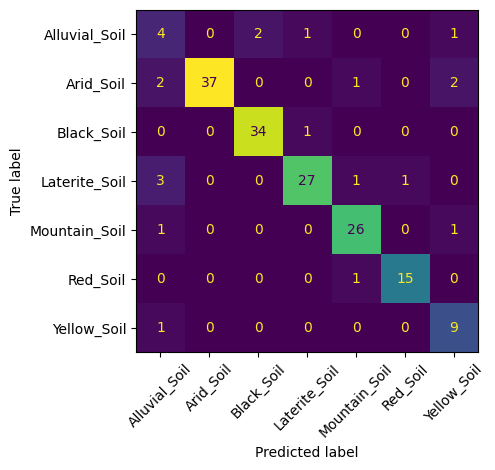

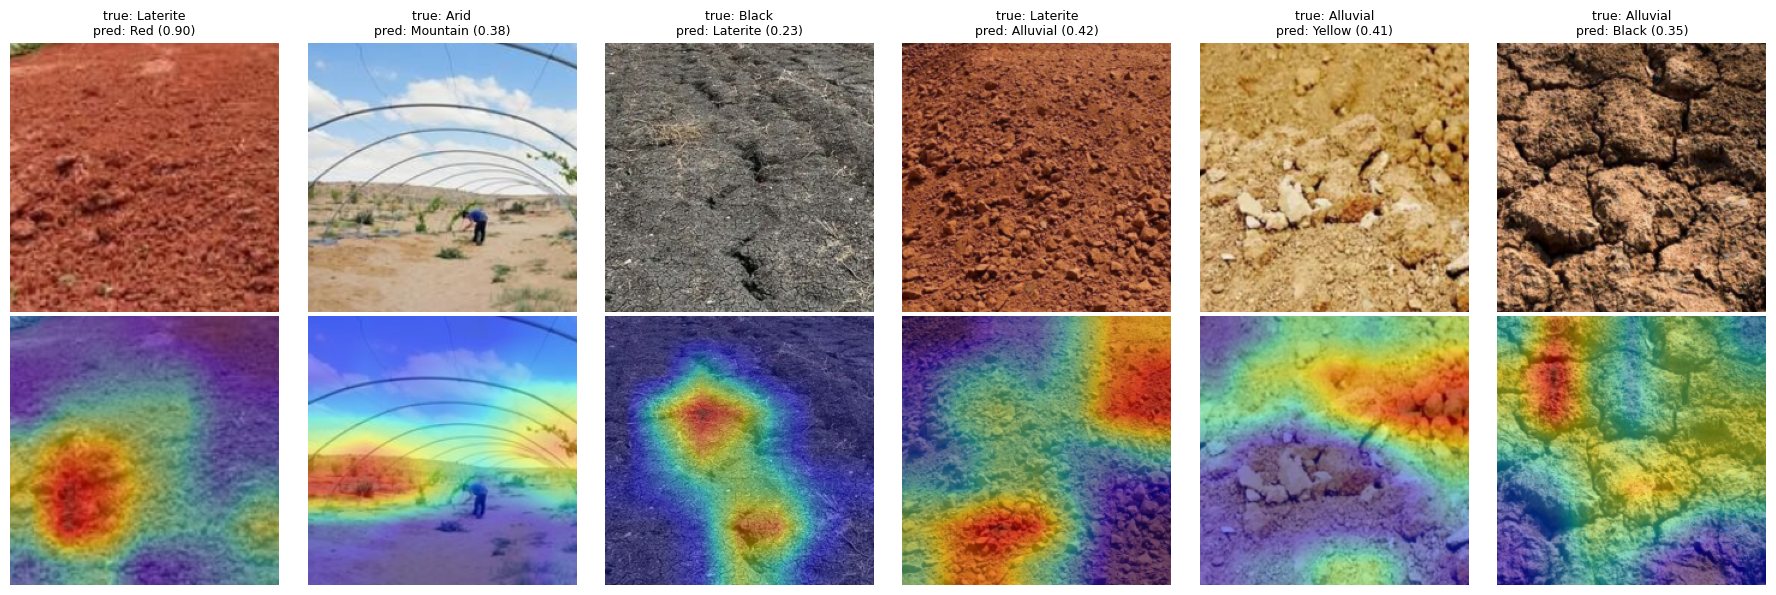

In [5]:
import matplotlib.pyplot as plt, torch.nn.functional as F
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model = model_A.eval()
ys, ps = evaluate(model, te)
ConfusionMatrixDisplay(confusion_matrix(ys, ps), display_labels=classes).plot(xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.show()

def grad_cam(model, x):
    store = {}
    def fwd(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.features[-1].register_forward_hook(fwd)
    out = model(x)
    idx = out.argmax(1).item()
    model.zero_grad(); out[0, idx].backward()
    h.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), idx, torch.softmax(out, 1)[0].detach().cpu().numpy()

te_r = te.reset_index(drop=True)
bad = [i for i, (y, p) in enumerate(zip(ys, ps)) if y != p][:6]
fig, axes = plt.subplots(2, len(bad), figsize=(3 * len(bad), 6))
for k, i in enumerate(bad):
    img = Image.open(te_r.path[i]).convert("RGB")
    cam, pred, probs = grad_cam(model, t_eval(img).unsqueeze(0).to(dev))
    shown = transforms.CenterCrop(224)(transforms.Resize(256)(img))
    axes[0, k].imshow(shown); axes[0, k].axis("off")
    axes[0, k].set_title(f"true: {classes[ys[i]][:-5]}\npred: {classes[pred][:-5]} ({probs[pred]:.2f})", fontsize=9)
    axes[1, k].imshow(shown); axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].axis("off")
plt.tight_layout(); plt.show()

In [6]:
def predict_probs(model, d):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y in DataLoader(DS(d, t_eval), batch_size=64, num_workers=2):
            P.append(torch.softmax(model(x.to(dev)), 1).cpu().numpy()); Y += y.tolist()
    return np.concatenate(P), np.array(Y)

for name, d in [("val", va), ("test", te)]:
    P, Y = predict_probs(model_A, d)
    conf, pred = P.max(1), P.argmax(1)
    print(f"\n{name} ({len(d)} images)")
    for t in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8]:
        keep = conf >= t
        print(f"  threshold {t:.1f}: answers {keep.mean():5.1%} of photos | accuracy on those {(pred[keep] == Y[keep]).mean():.3f}")


val (171 images)
  threshold 0.0: answers 100.0% of photos | accuracy on those 0.883
  threshold 0.4: answers 93.6% of photos | accuracy on those 0.906
  threshold 0.5: answers 85.4% of photos | accuracy on those 0.925
  threshold 0.6: answers 74.9% of photos | accuracy on those 0.945
  threshold 0.7: answers 62.0% of photos | accuracy on those 0.972
  threshold 0.8: answers 40.4% of photos | accuracy on those 0.986

test (171 images)
  threshold 0.0: answers 100.0% of photos | accuracy on those 0.889
  threshold 0.4: answers 91.8% of photos | accuracy on those 0.936
  threshold 0.5: answers 88.3% of photos | accuracy on those 0.954
  threshold 0.6: answers 82.5% of photos | accuracy on those 0.965
  threshold 0.7: answers 69.0% of photos | accuracy on those 0.975
  threshold 0.8: answers 48.5% of photos | accuracy on those 0.976


In [3]:
from pathlib import Path
base = next(Path("/kaggle/input").rglob("Orignal-Dataset")).parent

In [5]:
root = Path("/kaggle/input")
for pat in ("val2017", "*/val2017", "*/*/val2017", "*/*/*/val2017", "*/*/*/*/val2017"):
    for p in root.glob(pat):
        print(p)

In [1]:
import os, itertools
from pathlib import Path

def peek(root, max_depth=5, depth=0):
    try:
        with os.scandir(root) as it:
            entries = list(itertools.islice(it, 12))
    except Exception as e:
        print("  " * depth + f"(cannot read {root}: {e})")
        return
    dirs = [e for e in entries if e.is_dir()]
    files = [e.name for e in entries if not e.is_dir()][:3]
    print("  " * depth + f"{Path(root).name}/  -> {len(dirs)} sub-folders" + (f", files like {files}" if files else ""))
    if depth < max_depth:
        for d in sorted(dirs, key=lambda e: e.name)[:8]:
            peek(d.path, max_depth, depth + 1)

peek("/kaggle/input")

input/  -> 1 sub-folders
  datasets/  -> 2 sub-folders
    ai4a-lab/  -> 1 sub-folders
      comprehensive-soil-classification-datasets/  -> 2 sub-folders
        CyAUG-Dataset/  -> 7 sub-folders
          Alluvial_Soil/  -> 0 sub-folders, files like ['a (108).jpeg', 'a (327).jpeg', 'a (507).jpeg']
          Arid_Soil/  -> 0 sub-folders, files like ['208.jpg', '45.jpg', '56.jpg']
          Black_Soil/  -> 0 sub-folders, files like ['b (1262).jpeg', 'b (1118).jpeg', '218c.jpg']
          Laterite_Soil/  -> 0 sub-folders, files like ['45.jpg', '89.jpg', '20.jpg']
          Mountain_Soil/  -> 0 sub-folders, files like ['208.jpg', '45.jpg', '56.jpg']
          Red_Soil/  -> 0 sub-folders, files like ['r (251).jpeg', 'r (532).jpeg', 'r (573).jpeg']
          Yellow_Soil/  -> 0 sub-folders, files like ['y (2412).jpeg', 'y (1846).jpeg', 'y (1337).jpeg']
        Orignal-Dataset/  -> 7 sub-folders
          Alluvial_Soil/  -> 0 sub-folders, files like ['45.jpg', '20.jpg', '5.jpg']
          Ari

In [8]:
import zipfile
from pathlib import Path

z = Path("/kaggle/input/notebooks/derekxue/coco-2017-dataset/__output__.zip")
print("size (MB):", round(z.stat().st_size / 1e6))
with zipfile.ZipFile(z) as zf:
    names = zf.namelist()
print(len(names), "entries")
print(names[:15])

size (MB): 0
2 entries
['__pycache__/', 'temp_link/']


In [2]:
from pathlib import Path
root = Path("/kaggle/input")
for pat in ("val2017", "*/val2017", "*/*/val2017", "*/*/*/val2017", "*/*/*/*/val2017"):
    for p in root.glob(pat):
        print(p)

/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017


In [4]:
import os, hashlib
import numpy as np, pandas as pd
import torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score

base = Path("/kaggle/input/datasets/ai4a-lab/comprehensive-soil-classification-datasets")
exts = {".jpg", ".jpeg", ".png"}

# ---- real (original) soil images only, de-duplicated, stratified 70/15/15 ----
rows = []
for cls in sorted((base / "Orignal-Dataset").iterdir()):
    with os.scandir(cls) as it:
        for e in it:
            if Path(e.name).suffix.lower() in exts:
                rows.append(dict(path=e.path, label=cls.name, size=e.stat().st_size))
orig = pd.DataFrame(rows)

def fp(path, size):
    with open(path, "rb") as f:
        return hashlib.md5(f.read(65536)).hexdigest() + str(size)
orig["fp"] = [fp(p, s) for p, s in zip(orig.path, orig["size"])]
orig = orig.drop_duplicates("fp")

tr, tmp = train_test_split(orig, test_size=0.30, stratify=orig.label, random_state=42)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=42)
print("train / val / test:", len(tr), len(va), len(te), "(expect 797 / 171 / 171)")

# ---- training code (same as before) ----
dev = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
t_train = transforms.Compose([transforms.Resize(256), transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.ColorJitter(0.25, 0.25, 0.25, 0.03), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
t_eval = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class DS(Dataset):
    def __init__(self, d, tf):
        self.p, self.y, self.tf = d.path.tolist(), [c2i[l] for l in d.label], tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def evaluate(model, d):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in DataLoader(DS(d, t_eval), batch_size=64, num_workers=2):
            ps += model(x.to(dev)).argmax(1).cpu().tolist(); ys += y.tolist()
    return ys, ps

def run(train_df, name, epochs=12):
    torch.manual_seed(42)
    dl = DataLoader(DS(train_df, t_train), batch_size=32, shuffle=True, num_workers=2, drop_last=True)
    cnt = np.bincount([c2i[l] for l in train_df.label], minlength=len(classes))
    lw = torch.tensor(cnt.sum() / (len(classes) * cnt), dtype=torch.float32).to(dev)
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(classes))
    model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(weight=lw, label_smoothing=0.1)
    best_f1, best_state = -1, None
    for ep in range(epochs):
        model.train()
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); loss_fn(model(x), y).backward(); opt.step()
        sched.step()
        ys, ps = evaluate(model, va); f1 = f1_score(ys, ps, average="macro")
        print(f"[{name}] epoch {ep+1:02d}  val macro-F1 {f1:.3f}")
        if f1 > best_f1:
            best_f1, best_state = f1, {k: v.cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    ys, ps = evaluate(model, te)
    print(f"\n=== {name}: TEST ===")
    print(classification_report(ys, ps, target_names=classes, zero_division=0))
    torch.save({"state_dict": best_state, "classes": classes}, f"/kaggle/working/soil_cnn_{name}.pt")
    return model

train / val / test: 797 171 171 (expect 797 / 171 / 171)


In [5]:
import random
import pandas as pd
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

exts = {".jpg", ".jpeg", ".png"}
NEG_ROOTS = [Path("/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017")]
N_NEG = 600

def readable(p):
    try:
        with Image.open(p) as im: im.verify()
        return True
    except Exception:
        return False

neg_files = [p for root in NEG_ROOTS for p in root.iterdir() if p.suffix.lower() in exts]
print("negative images found:", len(neg_files))
random.seed(42)
picked = [p for p in random.sample(neg_files, min(N_NEG + 100, len(neg_files))) if readable(p)][:N_NEG]
neg = pd.DataFrame({"path": [str(p) for p in picked], "label": "Not_Soil"})

neg_tr, tmp = train_test_split(neg, test_size=0.30, random_state=42)
neg_va, neg_te = train_test_split(tmp, test_size=0.50, random_state=42)

va_soil, te_soil = va, te                                   # keep the soil-only splits
classes = sorted(orig.label.unique()) + ["Not_Soil"]
c2i = {c: i for i, c in enumerate(classes)}
va, te = pd.concat([va, neg_va]), pd.concat([te, neg_te])   # run() reads these globals
model_C = run(pd.concat([tr, neg_tr]), "C_with_not_soil")

negative images found: 5000
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 174MB/s]


[C_with_not_soil] epoch 01  val macro-F1 0.756
[C_with_not_soil] epoch 02  val macro-F1 0.746
[C_with_not_soil] epoch 03  val macro-F1 0.787
[C_with_not_soil] epoch 04  val macro-F1 0.819
[C_with_not_soil] epoch 05  val macro-F1 0.840
[C_with_not_soil] epoch 06  val macro-F1 0.823
[C_with_not_soil] epoch 07  val macro-F1 0.823
[C_with_not_soil] epoch 08  val macro-F1 0.858
[C_with_not_soil] epoch 09  val macro-F1 0.849
[C_with_not_soil] epoch 10  val macro-F1 0.846
[C_with_not_soil] epoch 11  val macro-F1 0.859
[C_with_not_soil] epoch 12  val macro-F1 0.849

=== C_with_not_soil: TEST ===
               precision    recall  f1-score   support

Alluvial_Soil       0.50      0.75      0.60         8
    Arid_Soil       0.95      0.90      0.93        42
   Black_Soil       1.00      0.97      0.99        35
Laterite_Soil       1.00      0.88      0.93        32
Mountain_Soil       0.93      0.93      0.93        28
     Red_Soil       0.94      1.00      0.97        16
  Yellow_Soil      

In [6]:
def predict_probs(model, d):
    model.eval(); P = []
    with torch.no_grad():
        for x, _ in DataLoader(DS(d, t_eval), batch_size=64, num_workers=2):
            P.append(torch.softmax(model(x.to(dev)), 1).cpu().numpy())
    return np.concatenate(P)

ns = classes.index("Not_Soil")
for name, d in [("val", va), ("test", te)]:
    P = predict_probs(model_C, d)
    y = np.array([c2i[l] for l in d.label]); conf = P.max(1); pred = P.argmax(1)
    soil, neg = y != ns, y == ns
    print(f"\n{name}: {soil.sum()} soil, {neg.sum()} non-soil photos")
    print(f"  real soil rejected as Not_Soil:     {(pred[soil] == ns).mean():.1%}")
    print(f"  non-soil accepted as soil (argmax): {(pred[neg] != ns).mean():.1%}")
    for t in [0.4, 0.5, 0.6, 0.7]:
        ok = (pred != ns) & (conf >= t)
        print(f"  conf>={t}: soil answered {ok[soil].mean():.1%} (accuracy {(pred[soil & ok] == y[soil & ok]).mean():.3f})"
              f" | non-soil slipping through {ok[neg].mean():.1%}")


val: 171 soil, 90 non-soil photos
  real soil rejected as Not_Soil:     0.0%
  non-soil accepted as soil (argmax): 2.2%
  conf>=0.4: soil answered 96.5% (accuracy 0.909) | non-soil slipping through 0.0%
  conf>=0.5: soil answered 88.9% (accuracy 0.934) | non-soil slipping through 0.0%
  conf>=0.6: soil answered 79.5% (accuracy 0.949) | non-soil slipping through 0.0%
  conf>=0.7: soil answered 70.2% (accuracy 0.967) | non-soil slipping through 0.0%

test: 171 soil, 90 non-soil photos
  real soil rejected as Not_Soil:     1.2%
  non-soil accepted as soil (argmax): 1.1%
  conf>=0.4: soil answered 95.3% (accuracy 0.945) | non-soil slipping through 0.0%
  conf>=0.5: soil answered 91.2% (accuracy 0.949) | non-soil slipping through 0.0%
  conf>=0.6: soil answered 80.1% (accuracy 0.978) | non-soil slipping through 0.0%
  conf>=0.7: soil answered 68.4% (accuracy 0.983) | non-soil slipping through 0.0%


In [7]:
from pathlib import Path
from collections import Counter

exts = {".jpg", ".jpeg", ".png"}
for root in sorted(Path("/kaggle/input/datasets").glob("*/*")):
    if any(k in root.name.lower() for k in ("arid", "gravel", "negative")):
        files = [f for f in root.rglob("*") if f.suffix.lower() in exts]
        print(f"\n{root}  ->  {len(files)} images")
        for folder, n in sorted(Counter(str(f.parent.relative_to(root)) for f in files).items()):
            print(f"   {folder or '.'}: {n}")


/kaggle/input/datasets/shankarinand500/arid-soil  ->  11 images
   .: 11

/kaggle/input/datasets/shankarinand500/gravel-soil  ->  10 images
   .: 10

/kaggle/input/datasets/shankarinand500/hard-negative  ->  21 images
   .: 21


In [8]:
from collections import Counter
from pathlib import Path
from PIL import Image

ns = classes.index("Not_Soil")

def tier_of(p):
    order = p.argsort()[::-1]
    if order[0] == ns: return "not_soil"
    top = p[order[0]]
    return "confident" if top >= 0.6 else "confirm" if top >= 0.4 else "retake"

def probe(folder):
    model_C.eval(); rows = []
    for f in sorted(Path(folder).iterdir()):
        if f.suffix.lower() not in exts: continue
        x = t_eval(Image.open(f).convert("RGB")).unsqueeze(0).to(dev)
        with torch.no_grad():
            p = torch.softmax(model_C(x), 1)[0].cpu().numpy()
        rows.append((f.name, classes[int(p.argmax())], round(float(p.max()), 2), tier_of(p)))
    return rows

for name in ("hard-negative", "arid-soil", "gravel-soil"):
    rows = probe(f"/kaggle/input/datasets/shankarinand500/{name}")
    print(f"\n== {name} ({len(rows)} images)")
    print("tiers:    ", dict(Counter(r[3] for r in rows)))
    print("top class:", dict(Counter(r[1] for r in rows)))
    if name == "hard-negative":
        print("non-soil photos that were NOT rejected:")
        for r in rows:
            if r[3] != "not_soil": print("  ", r)


== hard-negative (21 images)
tiers:     {'retake': 6, 'confirm': 9, 'confident': 2, 'not_soil': 4}
top class: {'Laterite_Soil': 3, 'Mountain_Soil': 1, 'Arid_Soil': 10, 'Not_Soil': 4, 'Black_Soil': 3}
non-soil photos that were NOT rejected:
   ('brown cloth.jpeg', 'Laterite_Soil', 0.31, 'retake')
   ('images (1).jpeg', 'Mountain_Soil', 0.29, 'retake')
   ('images (10).jpeg', 'Arid_Soil', 0.45, 'confirm')
   ('images (11).jpeg', 'Arid_Soil', 0.71, 'confident')
   ('images (16).jpeg', 'Black_Soil', 0.86, 'confident')
   ('images (17).jpeg', 'Laterite_Soil', 0.57, 'confirm')
   ('images (18).jpeg', 'Arid_Soil', 0.53, 'confirm')
   ('images (2).jpeg', 'Arid_Soil', 0.43, 'confirm')
   ('images (3).jpeg', 'Black_Soil', 0.44, 'confirm')
   ('images (4).jpeg', 'Arid_Soil', 0.51, 'confirm')
   ('images (5).jpeg', 'Arid_Soil', 0.51, 'confirm')
   ('images (6).jpeg', 'Black_Soil', 0.26, 'retake')
   ('images (7).jpeg', 'Arid_Soil', 0.41, 'confirm')
   ('images (8).jpeg', 'Arid_Soil', 0.39, 'retak

In [9]:
import random
from pathlib import Path
exts = {".jpg", ".jpeg", ".png"}

random.seed(42)
hard_picked = []
for key, n in {"bark": 150, "wood": 100}.items():
    roots = [r for r in Path("/kaggle/input/datasets").glob("*/*") if key in r.name.lower()]
    files = [f for r in roots for f in r.rglob("*") if f.suffix.lower() in exts]
    print(f"{key}: {len(files)} images in {[r.name for r in roots]}")
    hard_picked += [p for p in random.sample(files, min(n + 30, len(files))) if readable(p)][:n]

hard = pd.DataFrame({"path": [str(p) for p in hard_picked], "label": "Not_Soil"})
h_tr, tmp = train_test_split(hard, test_size=0.30, random_state=42)
h_va, h_te = train_test_split(tmp, test_size=0.50, random_state=42)

va = pd.concat([va_soil, neg_va, h_va])
te = pd.concat([te_soil, neg_te, h_te])
model_D = run(pd.concat([tr, neg_tr, h_tr]), "D_hard_negatives")

bark: 5578 images in ['barkvn50']
wood: 423 images in ['wood-samples']
[D_hard_negatives] epoch 01  val macro-F1 0.767
[D_hard_negatives] epoch 02  val macro-F1 0.766
[D_hard_negatives] epoch 03  val macro-F1 0.810
[D_hard_negatives] epoch 04  val macro-F1 0.787
[D_hard_negatives] epoch 05  val macro-F1 0.798
[D_hard_negatives] epoch 06  val macro-F1 0.816
[D_hard_negatives] epoch 07  val macro-F1 0.804
[D_hard_negatives] epoch 08  val macro-F1 0.817
[D_hard_negatives] epoch 09  val macro-F1 0.803
[D_hard_negatives] epoch 10  val macro-F1 0.781
[D_hard_negatives] epoch 11  val macro-F1 0.851
[D_hard_negatives] epoch 12  val macro-F1 0.832

=== D_hard_negatives: TEST ===
               precision    recall  f1-score   support

Alluvial_Soil       0.42      0.62      0.50         8
    Arid_Soil       0.95      0.86      0.90        42
   Black_Soil       1.00      0.97      0.99        35
Laterite_Soil       0.90      0.84      0.87        32
Mountain_Soil       0.90      0.93      0.91 

In [11]:
from IPython.display import FileLink
FileLink("soil_cnn_D_hard_negatives.pt")

/kaggle/working/soil_cnn_D_hard_negatives.pt